<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_4_modelos_fundacionales.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_4_modelos_fundacionales.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_4_modelos_fundacionales.ipynb)

# SI7011 · Sesión 06 · 4. Modelos fundacionales sin entrenar: CLIP y Chronos
**Juan David Martínez Vargas · Universidad EAFIT**

**Opcional, para la casa.** Acompaña la **Parte 4** de las diapositivas (55–59). Volvemos a dos problemas que ya resolviste, ahora con modelos preentrenados por otros a gran escala y usados **sin dar un solo paso de gradiente** sobre tus datos:

| Sección | Datos | Modelo | Contra qué |
|---|---|---|---|
| 1–3 | EuroSAT (sesiones 03 y 04) | CLIP zero-shot: la imagen contra un texto por clase | CLIP y ResNet-18 de ImageNet con sonda, 1 % y 10 % de las etiquetas |
| 4–5 | Bike Sharing (sesión 05) | Chronos-Bolt zero-shot: la serie como tokens | la base de sentido común: la misma hora de ayer |

La pregunta es la de la diapositiva 58: **zero-shot es una afirmación que hay que comprobar**.

**Usa GPU** (Kaggle T4, unos 10 minutos) y activa **Internet** en *Settings*: CLIP y Chronos se bajan de Hugging Face y Bike Sharing de UCI. EuroSAT: en Kaggle agrega `apollo2506/eurosat-dataset` con *Add Input* (el mismo de las sesiones 03 y 04); en Colab se baja con tu secreto `KAGGLE_API_TOKEN`.

In [1]:
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
import os
from importlib.metadata import version, PackageNotFoundError
try:
    if tuple(int(x) for x in version('torchao').split('.')[:2]) < (0, 16):
        os.system('pip uninstall -y -q torchao')
except (PackageNotFoundError, ValueError):
    pass

import hashlib, json, math, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split

try:
    import transformers
    from chronos import BaseChronosPipeline
except ImportError:                                         # chronos-forecasting no viene instalado
    os.system('pip install -q transformers chronos-forecasting')
    import transformers
    from chronos import BaseChronosPipeline
from transformers import CLIPModel, CLIPProcessor

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '· transformers', transformers.__version__, '·', dev)
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def desde_kaggle(handle):
    if kaggle_token() or Path('/kaggle/input').exists():
        try:
            import kagglehub                                # preinstalado en Colab y Kaggle
            return [Path(kagglehub.dataset_download(handle))]
        except Exception as e:
            print('kagglehub no disponible:', type(e).__name__)
    return []

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 2.2 MB/s eta 0:00:00
PyTorch 2.11.0+cu128 · transformers 5.16.1 · cuda


## 1. EuroSAT y CLIP
La misma partición 70/15/15 (`random_state=0`) de los integradores de las sesiones 03 y 04, así que los números se comparan con los tuyos. CLIP (diapositiva 55) tiene dos encoders, uno de imagen y otro de texto, entrenados con InfoNCE (sesión 04) sobre 400 millones de pares imagen–pie de foto de la web. Ambos llevan a vectores del mismo espacio, de norma 1.

In [2]:
EUROSAT = 'apollo2506/eurosat-dataset'

def find_rgb(roots):
    # El dataset trae EuroSAT/ (JPG, RGB) y EuroSATallBands/ (TIFF de 13 bandas): solo sirve la carpeta con JPG
    for root in [r for r in roots if r.exists()]:
        for d in sorted(root.rglob('AnnualCrop')):
            if d.is_dir() and next(d.glob('*.jpg'), None) is not None:
                return d.parent
    return None

folder = find_rgb(ROOTS) or find_rgb(desde_kaggle(EUROSAT))
ds = datasets.ImageFolder(folder) if folder else datasets.EuroSAT('data', download=True)
CLASSES = ds.classes; C = len(CLASSES)
X_all = torch.stack([torch.from_numpy(np.asarray(ds[i][0].convert('RGB')).copy()).permute(2, 0, 1) for i in range(len(ds))])
y_all = torch.tensor([label for _, label in ds.samples])
# la misma partición 70/15/15 de los integradores de las sesiones 03 y 04
idx_train, idx_rest = train_test_split(np.arange(len(y_all)), test_size=0.30, stratify=y_all, random_state=0)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=y_all[idx_rest], random_state=0)
print(f'{len(ds)} imágenes de {C} clases · entrenamiento {len(idx_train)} · validación {len(idx_val)}')

27000 imágenes de 10 clases · entrenamiento 18900 · validación 4050


In [3]:
CLIP = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP).to(dev).eval()
proc = CLIPProcessor.from_pretrained(CLIP)

def _salida(z):                                             # según la versión, un tensor o un objeto con pooler_output
    return z if torch.is_tensor(z) else z.pooler_output

@torch.no_grad()
def clip_imagenes(X, chunk=256):
    """Embeddings de imagen de CLIP, normalizados: X uint8 N × 3 × 64 × 64 (el procesador los lleva a 224)."""
    out = []
    for i in range(0, len(X), chunk):
        x = proc(images=list(X[i:i + chunk].permute(0, 2, 3, 1).numpy()), return_tensors='pt')['pixel_values'].to(dev)
        out.append(F.normalize(_salida(clip.get_image_features(pixel_values=x)).float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def clip_textos(textos):
    t = proc(text=textos, return_tensors='pt', padding=True).to(dev)
    return F.normalize(_salida(clip.get_text_features(**t)).float(), dim=-1).cpu()

t0 = time.time()
I_train, I_val = clip_imagenes(X_all[idx_train]), clip_imagenes(X_all[idx_val])
print(f'embeddings de imagen {tuple(I_train.shape)} en {time.time() - t0:.0f} s')

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

embeddings de imagen (18900, 512) en 84 s


## 2. Zero-shot
Para clasificar sin entrenar: un texto por clase, y cada imagen va a la clase cuyo texto tiene el coseno más alto. Las etiquetas de entrenamiento **no se usan**.

**Predice** (diapositiva 59): ¿qué accuracy esperas? Hay 10 clases: el azar da 0.10. ¿Importa cómo se escribe el texto?

In [4]:
NOMBRES = {'AnnualCrop': 'annual crop land', 'Forest': 'forest', 'HerbaceousVegetation': 'herbaceous vegetation',
           'Highway': 'a highway or a road', 'Industrial': 'industrial buildings', 'Pasture': 'pasture land',
           'PermanentCrop': 'permanent crop land', 'Residential': 'residential buildings', 'River': 'a river',
           'SeaLake': 'a sea or a lake'}
PLANTILLAS = {'nombre de la carpeta': '{c}',
              'una foto de ...': 'a photo of {n}.',
              'una foto satelital de ...': 'a satellite photo of {n}.'}
y_val = y_all[idx_val]
zs = {}
for nombre, p in PLANTILLAS.items():
    T = clip_textos([p.format(c=c, n=NOMBRES.get(c, c)) for c in CLASSES])     # una fila por clase
    pred = (I_val @ T.T).argmax(1)                                            # el texto más parecido
    zs[nombre] = (pred == y_val).float().mean().item()
    print(f'zero-shot, plantilla {nombre!r:<30} accuracy de validación {zs[nombre]:.3f}')
T_mejor = clip_textos([PLANTILLAS['una foto satelital de ...'].format(n=NOMBRES.get(c, c)) for c in CLASSES])

zero-shot, plantilla 'nombre de la carpeta'         accuracy de validación 0.365
zero-shot, plantilla 'una foto de ...'              accuracy de validación 0.374
zero-shot, plantilla 'una foto satelital de ...'    accuracy de validación 0.408


La redacción importa: *AnnualCrop* no es una frase que aparezca en los pies de foto de la web, *a satellite photo of annual crop land* se acerca más. Eso es **ingeniería de prompts**: elegir textos con las etiquetas de validación ya es usar etiquetas, aunque sean pocas.

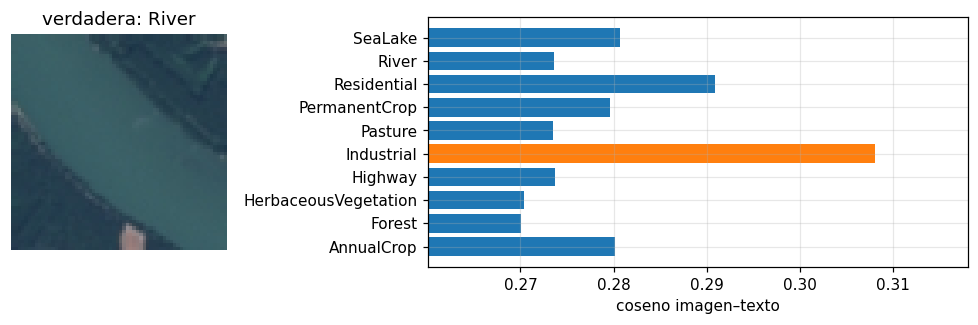

In [5]:
k = int((y_val == CLASSES.index('River')).nonzero()[0, 0]) if 'River' in CLASSES else 0
sim = (I_val[k] @ T_mejor.T)
np.savez_compressed('clip_zeroshot.npz', imagen=X_all[idx_val[k]].permute(1, 2, 0).numpy(), clases=np.array(CLASSES),
                    similitud=sim.numpy(), prob=(100 * sim).softmax(0).numpy(), verdadera=int(y_val[k]))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={'width_ratios': [1, 2.5]})
a0.imshow(X_all[idx_val[k]].permute(1, 2, 0)); a0.axis('off'); a0.set_title(f'verdadera: {CLASSES[int(y_val[k])]}')
a1.barh(CLASSES, sim.numpy(), color=['C1' if i == sim.argmax() else 'C0' for i in range(C)])
a1.set_xlim(sim.min().item() - 0.01, sim.max().item() + 0.01); a1.set_xlabel('coseno imagen–texto')
plt.tight_layout(); plt.show()

## 3. Las mismas features, con una sonda
¿El problema está en las features de CLIP o en los textos? Entrenamos la sonda lineal de la sesión 04 sobre los embeddings de imagen de CLIP con 1 % y 10 % de las etiquetas, y lo mismo con la ResNet-18 de ImageNet (sesión 03). Tres semillas por fracción.

In [6]:
def submuestra(y, frac, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.cat([(y == c).nonzero().squeeze(1)[torch.randperm(int((y == c).sum()), generator=g)[:max(1, round(frac * int((y == c).sum())))]]
                      for c in range(C)])

def sonda(Htr, ytr, Hev, yev, pasos=300, seed=0):
    """La sonda lineal de la sesión 04: features estandarizadas, una capa lineal, Adam."""
    mu, sd = Htr.mean(0), Htr.std(0) + 1e-6
    torch.manual_seed(seed)
    W = nn.Linear(Htr.shape[1], C)
    opt = torch.optim.Adam(W.parameters(), lr=1e-2, weight_decay=1e-4)
    for _ in range(pasos):
        loss = F.cross_entropy(W((Htr - mu) / sd), ytr)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (W((Hev - mu) / sd).argmax(1) == yev).float().mean().item()

@torch.no_grad()
def resnet_imagenet(X, chunk=500):
    w = ResNet18_Weights.IMAGENET1K_V1
    g = resnet18(weights=w).to(dev).eval(); g.fc = nn.Identity()
    m, s = torch.tensor(w.transforms().mean).view(1, 3, 1, 1).to(dev), torch.tensor(w.transforms().std).view(1, 3, 1, 1).to(dev)
    return torch.cat([g((X[i:i + chunk].to(dev).float() / 255 - m) / s).cpu() for i in range(0, len(X), chunk)])

y_train = y_all[idx_train]
H = {'CLIP (imagen)': (I_train, I_val), 'ResNet-18 ImageNet': (resnet_imagenet(X_all[idx_train]), resnet_imagenet(X_all[idx_val]))}
filas = [{'encoder': 'CLIP zero-shot', 'etiquetas': '0 %', 'accuracy': zs['una foto satelital de ...']}]
for nombre, (Htr, Hva) in H.items():
    for frac in (0.01, 0.10):
        accs = [sonda(Htr[i], y_train[i], Hva, y_val, seed=s) for s in (0, 1, 2) for i in [submuestra(y_train, frac, s)]]
        filas.append({'encoder': nombre + ' + sonda', 'etiquetas': f'{frac:.0%}', 'accuracy': float(np.mean(accs))})
tabla_eurosat = pd.DataFrame(filas)
print(tabla_eurosat.round(3).to_string(index=False))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]


                   encoder etiquetas  accuracy
            CLIP zero-shot       0 %     0.408
     CLIP (imagen) + sonda        1%     0.860
     CLIP (imagen) + sonda       10%     0.930
ResNet-18 ImageNet + sonda        1%     0.796
ResNet-18 ImageNet + sonda       10%     0.878


Compara con tu tabla del integrador de la sesión 04 (SimCLR sobre EuroSAT sin etiquetas, con 1 % y 10 %). Lo esperable: CLIP zero-shot está muy por encima del azar pero lejos de una sonda; con unas pocas etiquetas, la sonda sobre las **mismas** features de CLIP sube mucho. La información estaba en las features; el texto no llegaba a ella. Las fotos satelitales son raras entre los pies de foto de la web.

## 4. Bike Sharing y Chronos
Demanda de bicicletas por hora en Washington D. C., 2011–2012 (UCI), la serie del integrador de la sesión 05. Los últimos meses quedan para evaluar: **partición temporal**, como en la sesión 05.

Chronos (diapositiva 57) escala cada serie, convierte sus valores en tokens y fue preentrenado como un modelo de lenguaje sobre muchas series, reales y sintéticas. Chronos-Bolt predice directamente varios cuantiles del futuro. Le damos las últimas 512 horas y le pedimos las 24 siguientes, a medianoche de cada día de evaluación.

In [7]:
UCI = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'

def buscar(nombre, roots):
    for r in [r for r in roots if r.exists()]:
        hits = sorted(r.rglob(nombre))
        if hits:
            return hits[0]
    return None

ruta = buscar('hour.csv', ROOTS)
if ruta is None:                                            # se baja de UCI (Kaggle: Internet activado)
    import io, urllib.request, zipfile
    Path('data').mkdir(exist_ok=True)
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(UCI).read())).extract('hour.csv', 'data')
    ruta = Path('data/hour.csv')
bike = pd.read_csv(ruta, parse_dates=['dteday'])
bike['t'] = bike['dteday'] + pd.to_timedelta(bike['hr'], unit='h')
serie = bike.set_index('t')['cnt'].asfreq('h').interpolate()      # 2 años por hora; unas pocas horas faltan
y = serie.to_numpy(dtype=np.float32)
corte = int(0.8 * len(y))                                     # los últimos meses, para evaluar (partición temporal)
print(f'{ruta} · {len(y):,} horas · evaluación desde {serie.index[corte]:%Y-%m-%d}')

data/hour.csv · 17,544 horas · evaluación desde 2012-08-07


**Predice:** ¿le gana Chronos a "la misma hora de ayer"? ¿En qué horizontes?

In [8]:
H_MAX, CONTEXTO = 24, 512
origenes = [o for o in range(corte, len(y) - H_MAX) if serie.index[o].hour == 0]   # una predicción por día, a medianoche
real = np.stack([y[o:o + H_MAX] for o in origenes])

ayer = np.stack([y[o - 24:o - 24 + H_MAX] for o in origenes])          # la base de sentido común: la misma hora de ayer
semana = np.stack([y[o - 168:o - 168 + H_MAX] for o in origenes])      # la misma hora, hace una semana

chronos = BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small', device_map=dev, torch_dtype=torch.float32)

def pronosticar(contextos, h=H_MAX, B=64):
    """Cuantiles 0.1, 0.5 y 0.9 de las próximas h horas para cada contexto: sin entrenar nada."""
    qs = []
    for i in range(0, len(contextos), B):
        q, _ = chronos.predict_quantiles(torch.tensor(np.stack(contextos[i:i + B])), prediction_length=h,
                                         quantile_levels=[0.1, 0.5, 0.9])
        qs.append(q.float().cpu().numpy())
    return np.concatenate(qs)

t0 = time.time()
Q = pronosticar([y[o - CONTEXTO:o] for o in origenes])
print(f'{len(origenes)} pronósticos de {H_MAX} h en {time.time() - t0:.1f} s · forma {Q.shape}')

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

145 pronósticos de 24 h en 0.4 s · forma (145, 24, 3)


## 5. ¿Le gana a la base?
MAE por horizonte (1, 6, 12 y 24 horas) contra dos bases de sentido común, y si el intervalo 10–90 % contiene al valor real con la frecuencia que promete.

               misma hora de ayer  misma hora hace una semana  Chronos-Bolt zero-shot (mediana)
horizonte (h)                                                                                  
1                       38.700001                        26.0                         15.700000
6                       12.100000                         9.4                          7.300000
12                      98.699997                        65.5                         51.700001
24                      41.000000                        37.0                         27.299999

promedio de las 24 horas: {'misma hora de ayer': 79.5, 'misma hora hace una semana': 67.19999694824219, 'Chronos-Bolt zero-shot (mediana)': 47.70000076293945}
el intervalo 10–90 % de Chronos contiene el valor real el 80% de las veces (ideal: 80 %)


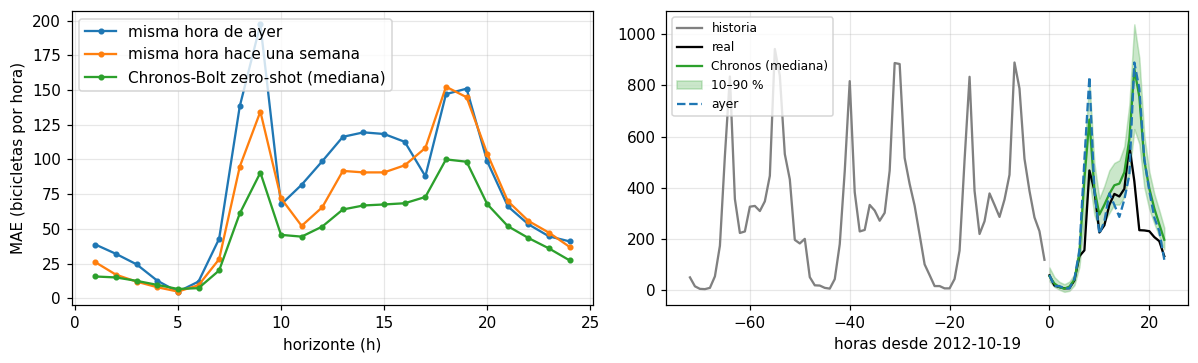

In [9]:
mae = lambda p: np.abs(p - real).mean(0)                     # MAE por horizonte
res = pd.DataFrame({'misma hora de ayer': mae(ayer), 'misma hora hace una semana': mae(semana),
                    'Chronos-Bolt zero-shot (mediana)': mae(Q[..., 1])}, index=np.arange(1, H_MAX + 1))
res.index.name = 'horizonte (h)'
print(res.loc[[1, 6, 12, 24]].round(1).to_string())
print('\npromedio de las 24 horas:', res.mean().round(1).to_dict())
cobertura = ((real >= Q[..., 0]) & (real <= Q[..., 2])).mean()
print(f'el intervalo 10–90 % de Chronos contiene el valor real el {cobertura:.0%} de las veces (ideal: 80 %)')

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.4))
res.plot(ax=a0, marker='o', ms=3); a0.set_ylabel('MAE (bicicletas por hora)')
j = len(origenes) // 2
h = np.arange(-72, H_MAX)
a1.plot(h[:72], y[origenes[j] - 72:origenes[j]], color='gray', label='historia')
a1.plot(np.arange(H_MAX), real[j], 'k', label='real')
a1.plot(np.arange(H_MAX), Q[j, :, 1], color='C2', label='Chronos (mediana)')
a1.fill_between(np.arange(H_MAX), Q[j, :, 0], Q[j, :, 2], color='C2', alpha=0.25, label='10–90 %')
a1.plot(np.arange(H_MAX), ayer[j], color='C0', ls='--', label='ayer')
a1.set_xlabel(f'horas desde {serie.index[origenes[j]]:%Y-%m-%d}'); a1.legend(fontsize=8)
plt.tight_layout(); plt.show()

Chronos solo ve la serie: no sabe del clima, de los festivos ni de que es fin de semana, que tu LSTM de la sesión 05 sí usaba. Si le gana a la base, es con información que tú no le diste; si no, la diapositiva 58 tenía razón. Compara también con el MAE por horizonte de tu integrador de la sesión 05.

In [10]:
json.dump({'eurosat': {'zero_shot': zs, 'tabla': tabla_eurosat.to_dict('records')},
           'bike': {'mae_por_horizonte': res.to_dict('list'), 'cobertura_10_90': float(cobertura),
                    'origenes': len(origenes), 'contexto': CONTEXTO}},
          open('resultados_fundacionales.json', 'w'), ensure_ascii=False, indent=1)
print('guardado: resultados_fundacionales.json y clip_zeroshot.npz')

guardado: resultados_fundacionales.json y clip_zeroshot.npz


## Tu turno
1. **Otra plantilla.** Escribe tus propios textos para las 10 clases (en inglés). ¿Cuánto puedes subir el zero-shot? ¿Por qué eso ya no es "cero" etiquetas?
2. **Contexto.** Chronos con `CONTEXTO = 48` y `CONTEXTO = 2048`. ¿Cuánta historia necesita para ver el ciclo semanal?
3. **Horizonte largo.** `H_MAX = 64` (el máximo de Chronos-Bolt). ¿Dónde deja de ganarle a "hace una semana"?
4. **Un modelo más grande.** `amazon/chronos-bolt-base` y `openai/clip-vit-large-patch14`. ¿Cuánto mejora, y cuánto más tarda?

In [11]:
# Tu turno

### Referencias
- Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision*, ICML (CLIP).
- Ansari et al. (2024), *Chronos: Learning the Language of Time Series*, TMLR; Chronos-Bolt, Amazon Science (2024).
- Helber et al. (2019), *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE JSTARS.
- Fanaee-T y Gama (2014), *Event labeling combining ensemble detectors and background knowledge*, Progress in AI (Bike Sharing, UCI).